# 🏁 F1 Podium Predictor — 77 seasons of Formula 1 (1950 → Brazil 2026)
**Hussain Ahmed** · Data & Machine Learning

**Data:** *Formula 1 World Championship (1950 - 2026)* by Samuel_Pbq on Kaggle — Jolpica-F1 / Ergast tables,
1,169 races up to the 2026 Brazilian GP (round 20). License **CC BY-NC-SA 4.0** (non-commercial, share-alike).

**Plan**
1. **Analysis** — what 77 seasons say about poles, reliability, pit stops, circuits, dominance and the new 2026 rules.
2. **Model** — *before the lights go out*, what is each driver's probability of finishing on the podium?
   Leak-free features only (Saturday's grid + everything before the race), season-forward validation,
   Optuna tuning, held-out test on **2023–2026**.
3. **Explain** — SHAP, calibration, and race-level case studies.

In [1]:
import sys, json, warnings
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import optuna, shap, joblib
from lightgbm import LGBMClassifier
from sklearn.calibration import calibration_curve

import style
from style import BLUE, ORANGE, AQUA, GRAY, INK, INK_2, MUTED
from features import load_tables, base_results, build_features, FEATURES, TARGET, RAW
from modeling import make_models, season_forward_cv, metrics, race_top3_hits, race_winner_hit, TEST_YEARS, CV_YEARS, SEED

RAW_DIR = "../" + RAW
FIG, RES = "../figures/", "../results/"
style.apply()
pd.set_option("display.width", 160)
facts = {}

## 1. Load & sanity-check

In [2]:
t = load_tables(RAW_DIR)
for k, v in t.items():
    print(f"{k:24s} {v.shape}")
res = base_results(t)
facts["n_races"] = int(t["races"].raceId.nunique()); facts["n_seasons"] = int(t["races"].year.nunique())
facts["last_race"] = t["races"].sort_values("raceId").iloc[-1][["year", "round", "name", "date"]].astype(str).to_dict()
winners_per_race = res.groupby("raceId").positionOrder.apply(lambda s: (s == 1).sum())
print("races with a shared win (1950s shared drives, documented in the source):", (winners_per_race != 1).sum())
assert winners_per_race[res.groupby("raceId").year.first() >= 1960].eq(1).all()
facts

races                    (1169, 18)
results                  (26313, 18)
status                   (136, 2)
drivers                  (835, 9)
constructors             (205, 5)
circuits                 (78, 9)
qualifying               (11410, 9)
driver_standings         (35072, 7)
constructor_standings    (13701, 7)
pit_stops                (13029, 7)
sprint_results           (612, 16)
races with a shared win (1950s shared drives, documented in the source): 3


{'n_races': 1169,
 'n_seasons': 77,
 'last_race': {'year': '2026',
  'round': '20',
  'name': 'Brazilian Grand Prix',
  'date': '2026-11-08'}}

**Classification rule** — `status` is *Finished*, *Lapped* or *+N Laps* → classified; *Did not start / Withdrew / DNQ*
→ removed; anything else (Retired, Accident, Engine, …) → **DNF**.

## 2. Analysis — 7 stories in the data

### 2.1 Pole position is worth more than ever

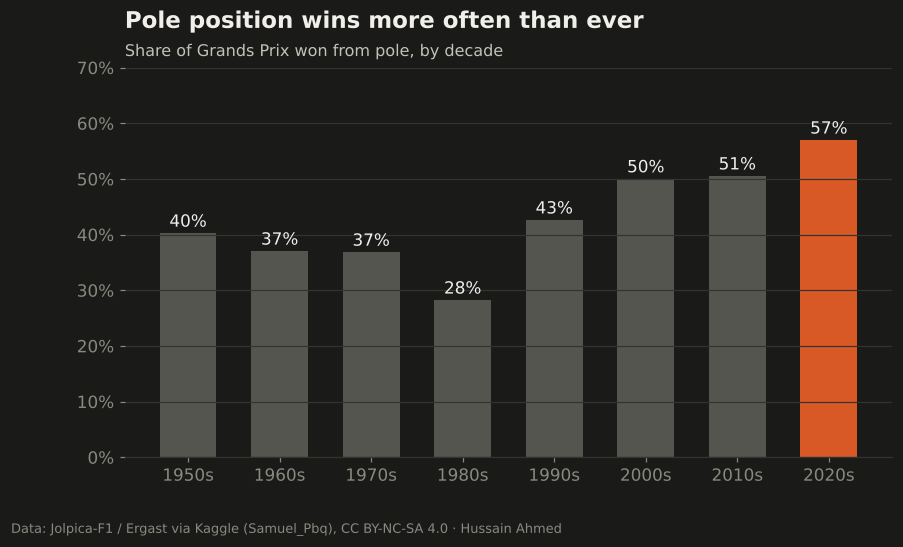

In [3]:
wins = res[res.positionOrder == 1].copy()
wins["decade"] = wins.year // 10 * 10
pole = (wins.grid == 1).groupby(wins.decade).mean()
facts["pole_win_rate_by_decade"] = pole.round(3).to_dict()
fig, ax = plt.subplots(figsize=(9, 4.6))
bars = ax.bar(pole.index.astype(str) + "s", pole.values * 100, color=[GRAY] * (len(pole) - 1) + [ORANGE], width=0.62)
for b, v in zip(bars, pole.values):
    ax.text(b.get_x() + b.get_width() / 2, v * 100 + 1.2, f"{v:.0%}", ha="center", color=INK, fontsize=11)
ax.set_ylim(0, 70); ax.yaxis.set_major_formatter(mtick.PercentFormatter()); ax.grid(axis="x", visible=False)
ax.set_title("Pole position wins more often than ever")
style.subtitle(ax, "Share of Grands Prix won from pole, by decade")
style.source(fig); plt.savefig(FIG + "01_pole_to_win.png"); plt.show()

### 2.2 Since 2010, the grid slot almost decides the podium

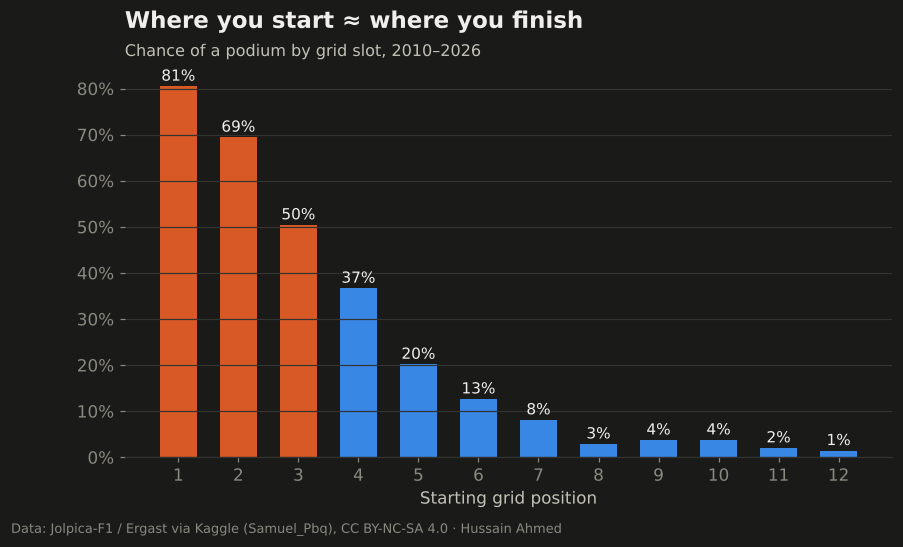

In [4]:
mod = res[(res.year >= 2010) & ~res.dns & (res.grid > 0)]
pg = mod.groupby("grid").podium.mean().loc[1:12]
facts["p_podium_by_grid_2010plus"] = pg.round(3).to_dict()
fig, ax = plt.subplots(figsize=(9, 4.6))
cols = [ORANGE if g <= 3 else BLUE for g in pg.index]
bars = ax.bar(pg.index.astype(str), pg.values * 100, color=cols, width=0.62)
for b, v in zip(bars, pg.values):
    ax.text(b.get_x() + b.get_width() / 2, v * 100 + 1.2, f"{v:.0%}", ha="center", color=INK, fontsize=10)
ax.set_xlabel("Starting grid position"); ax.yaxis.set_major_formatter(mtick.PercentFormatter()); ax.grid(axis="x", visible=False)
ax.set_title("Where you start ≈ where you finish")
style.subtitle(ax, "Chance of a podium by grid slot, 2010–2026")
style.source(fig); plt.savefig(FIG + "02_podium_by_grid.png"); plt.show()

### 2.3 The greatest comebacks — and one is from 2026

In [5]:
far = wins.sort_values("grid", ascending=False).head(8).merge(t["drivers"][["driverId", "forename", "surname"]], on="driverId")
far = far[["year", "name", "grid", "forename", "surname"]]
facts["furthest_back_winners"] = far.head(5).astype(str).to_dict(orient="records")
far

,year,name,grid,forename,surname
0,1983,United States Grand Prix West,22,John,Watson
1,1954,Indianapolis 500,19,Bill,Vukovich
2,2026,Italian Grand Prix,19,Andrea Kimi,Antonelli
3,2000,German Grand Prix,18,Rubens,Barrichello
4,2005,Japanese Grand Prix,17,Kimi,Räikkönen
5,1982,Detroit Grand Prix,17,John,Watson
6,2024,São Paulo Grand Prix,17,Max,Verstappen
7,1973,South African Grand Prix,16,Jackie,Stewart


### 2.4 Reliability: 2026's new rules brought the retirements back

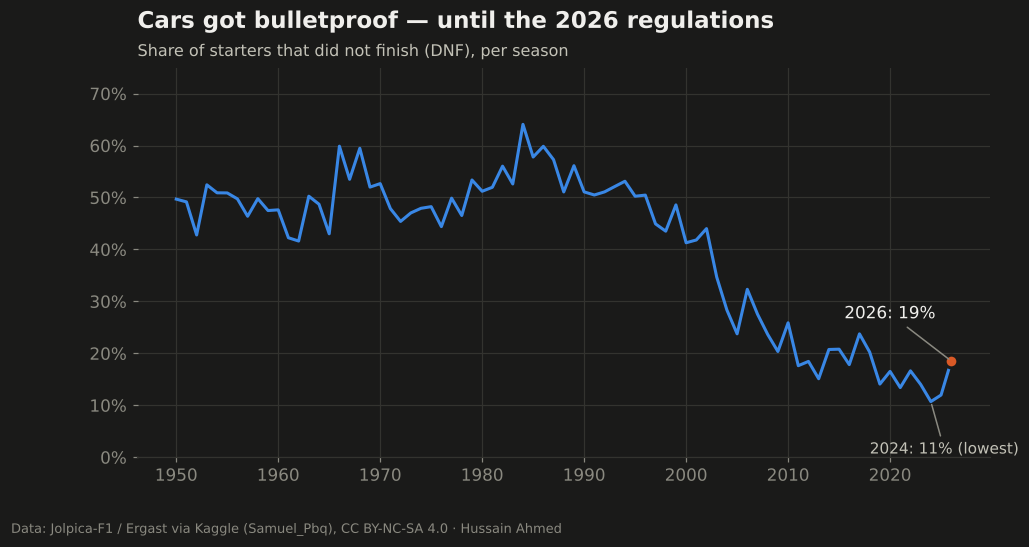

In [6]:
starters = res[~res.dns]
dnf_year = starters.groupby("year").dnf.mean()
facts["dnf_rate"] = {int(y): round(float(v), 3) for y, v in dnf_year.loc[[1960, 1980, 2000, 2010, 2019, 2024, 2025, 2026]].items()}
fig, ax = plt.subplots(figsize=(10, 4.6))
ax.plot(dnf_year.index, dnf_year.values * 100, color=BLUE)
ax.scatter([2026], [dnf_year.loc[2026] * 100], color=ORANGE, s=70, zorder=3, edgecolor=style.SURFACE, linewidth=2)
low = dnf_year.loc[2000:].idxmin()
ax.annotate(f"2026: {dnf_year.loc[2026]:.0%}", (2026, dnf_year.loc[2026] * 100), xytext=(-70, 28), textcoords="offset points",
            color=INK, fontsize=11, arrowprops=dict(arrowstyle="-", color=MUTED))
ax.annotate(f"{low}: {dnf_year.loc[low]:.0%} (lowest)", (low, dnf_year.loc[low] * 100), xytext=(-40, -34),
            textcoords="offset points", color=INK_2, fontsize=10, arrowprops=dict(arrowstyle="-", color=MUTED))
ax.yaxis.set_major_formatter(mtick.PercentFormatter()); ax.set_ylim(0, 75)
ax.set_title("Cars got bulletproof — until the 2026 regulations")
style.subtitle(ax, "Share of starters that did not finish (DNF), per season")
style.source(fig); plt.savefig(FIG + "03_dnf_rate.png"); plt.show()
facts["dnf_lowest_year_since_2000"] = int(low); facts["dnf_lowest_value"] = round(float(dnf_year.loc[low]), 3)

### 2.5 Pit stops: the crew got faster, the pit lane did not

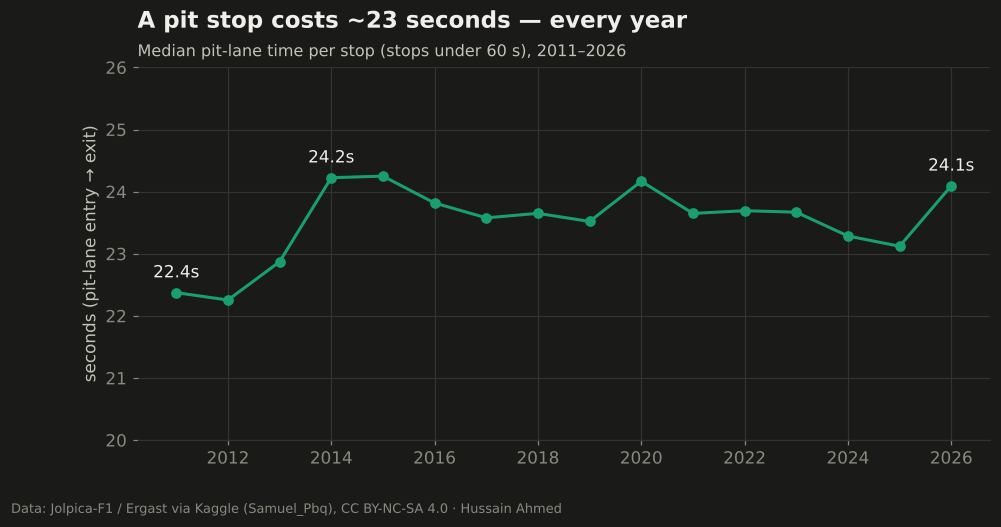

In [7]:
pit = t["pit_stops"].merge(t["races"][["raceId", "year"]], on="raceId")
pit["sec"] = pit.milliseconds / 1000
pit = pit[pit.sec < 60]           # removes red-flag 'stops' that last minutes
pit_med = pit.groupby("year").sec.median()
facts["pit_median_sec"] = pit_med.round(2).to_dict()
facts["pit_stops_used"] = int(len(pit))
fig, ax = plt.subplots(figsize=(10, 4.4))
ax.plot(pit_med.index, pit_med.values, color=AQUA, marker="o", markersize=6)
ax.set_ylim(20, 26); ax.set_ylabel("seconds (pit-lane entry → exit)")
for y in [2011, 2014, 2026]:
    ax.annotate(f"{pit_med.loc[y]:.1f}s", (y, pit_med.loc[y]), xytext=(0, 10), textcoords="offset points", ha="center", color=INK)
ax.set_title("A pit stop costs ~23 seconds — every year")
style.subtitle(ax, "Median pit-lane time per stop (stops under 60 s), 2011–2026")
style.source(fig); plt.savefig(FIG + "04_pit_stops.png"); plt.show()

### 2.6 Where pole matters most (and least)

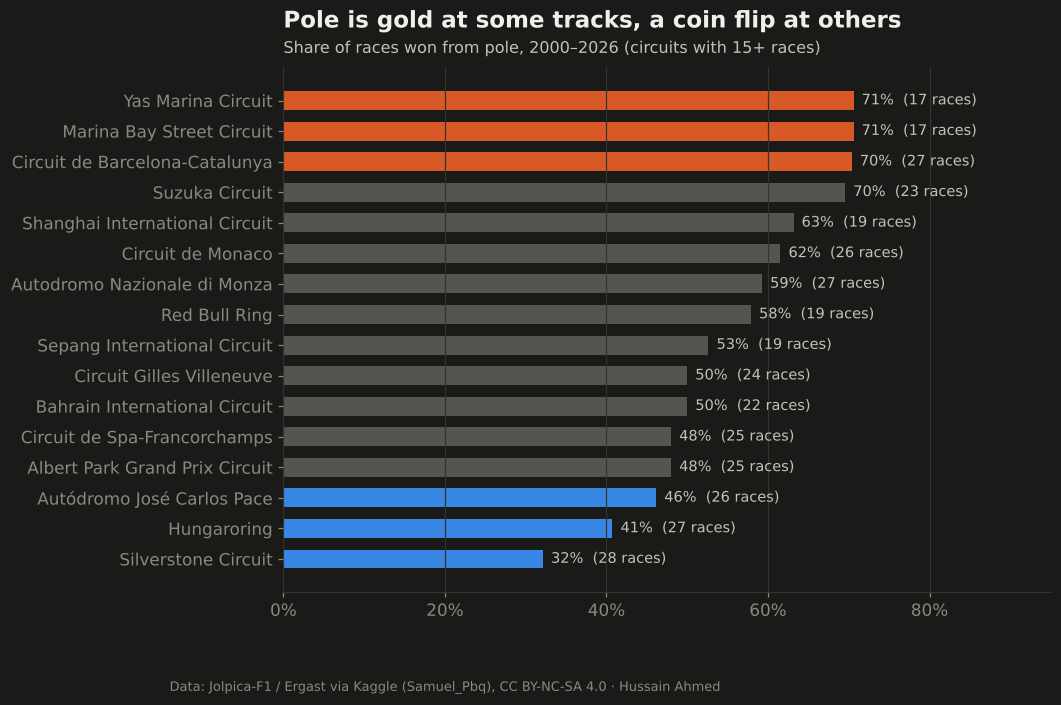

In [8]:
cw = wins[wins.year >= 2000].merge(t["circuits"][["circuitId", "name"]].rename(columns={"name": "circuit"}), on="circuitId")
circ = cw.groupby("circuit").agg(races=("grid", "size"), pole_win=("grid", lambda s: (s == 1).mean())).query("races >= 15")
circ = circ.sort_values("pole_win")
facts["circuit_pole_win"] = circ.round(3).reset_index().to_dict(orient="records")
fig, ax = plt.subplots(figsize=(9, 6.2))
c = [ORANGE if i >= len(circ) - 3 else BLUE if i < 3 else GRAY for i in range(len(circ))]
ax.barh(circ.index, circ.pole_win * 100, color=c, height=0.62)
for i, (v, n) in enumerate(zip(circ.pole_win, circ.races)):
    ax.text(v * 100 + 1, i, f"{v:.0%}  ({n} races)", va="center", color=INK_2, fontsize=9.5)
ax.xaxis.set_major_formatter(mtick.PercentFormatter()); ax.set_xlim(0, 95); ax.grid(axis="y", visible=False)
ax.set_title("Pole is gold at some tracks, a coin flip at others")
style.subtitle(ax, "Share of races won from pole, 2000–2026 (circuits with 15+ races)")
style.source(fig); plt.savefig(FIG + "05_circuits_pole.png"); plt.show()

### 2.7 Dominance — and the 2026 title fight

In [9]:
cwin = wins.groupby(["year", "constructorId"]).size().rename("w").reset_index()
cwin["share"] = cwin.w / cwin.year.map(wins.groupby("year").size())
top = cwin.loc[cwin.groupby("year").share.idxmax()].merge(t["constructors"][["constructorId", "name"]], on="constructorId")
facts["most_dominant_seasons"] = top.sort_values("share", ascending=False).head(5)[["year", "name", "w", "share"]].round(3).to_dict(orient="records")
top.sort_values("share", ascending=False).head(6)

,year,constructorId,w,share,name
73,2023,191,21,0.954545,Red Bull
38,1988,117,15,0.937500,McLaren
66,2016,48,19,0.904762,Mercedes
52,2002,6,15,0.882353,Ferrari
2,1952,6,7,0.875000,Ferrari
0,1950,1,6,0.857143,Alfa Romeo


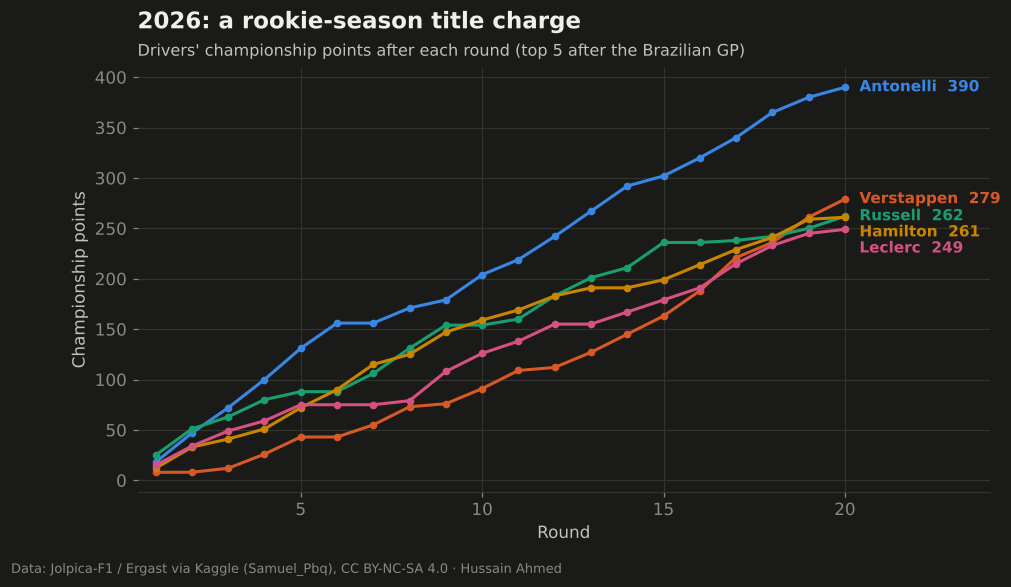

In [10]:
ds = t["driver_standings"].merge(t["races"][["raceId", "year", "round"]], on="raceId")
s26 = ds[ds.year == 2026].merge(t["drivers"][["driverId", "surname"]], on="driverId")
last = s26[s26["round"] == s26["round"].max()].sort_values("position")
lead5 = last.head(5).surname.tolist()
facts["standings_2026_latest"] = last.head(5)[["surname", "points", "wins"]].to_dict(orient="records")
facts["winners_2026"] = res[(res.year == 2026) & (res.positionOrder == 1)].merge(t["drivers"], on="driverId").surname.value_counts().to_dict()
fig, ax = plt.subplots(figsize=(10, 5))
ends = []
for i, name in enumerate(lead5):
    d = s26[s26.surname == name].sort_values("round")
    ax.plot(d["round"], d.points, color=style.SERIES[i], marker="o", markersize=4)
    ends.append([d.points.iloc[-1], name, style.SERIES[i], d["round"].iloc[-1]])
# spread end labels so they never overlap (min 16 points apart)
ends.sort(key=lambda e: -e[0]); ys = []
for e in ends:
    y = e[0] if not ys else min(e[0], ys[-1] - 16); ys.append(y)
for (pts, name, col, rnd), y in zip(ends, ys):
    ax.text(rnd + 0.4, y, f"{name}  {pts:.0f}", color=col, va="center", fontsize=10, fontweight="bold")
ax.set_xlim(0.5, s26["round"].max() + 4); ax.set_xlabel("Round"); ax.set_ylabel("Championship points")
ax.set_title("2026: a rookie-season title charge")
style.subtitle(ax, "Drivers' championship points after each round (top 5 after the Brazilian GP)")
style.source(fig); plt.savefig(FIG + "06_title_fight_2026.png"); plt.show()

## 3. Model — podium probability before the race
**Unit:** one row per driver per race, 2006–2026 (2003–2005 only warm up the rolling statistics).

**Features (27), all known before the start:** grid & qualifying (position, % gap to pole, Q3 reached, gap to team-mate),
driver form (last 5/10 races: average finish, podium/win/DNF rate, places gained, experience, career podiums),
team form (best finish, podium & DNF rate), championship position and points share *after the previous round*,
circuit history (driver's past results there, how much the grid usually shuffles there), sprint weekend, season stage.
All rolling stats use `shift(1)` so the current race never leaks into its own features.

**Validation:** season-forward — for each season 2018–2022, train on every earlier season and predict that season.
**Test:** 2023–2026 (90 races), untouched until the end.

In [11]:
df = build_features(t)
dev, test = df[~df.year.isin(TEST_YEARS)], df[df.year.isin(TEST_YEARS)]
print(df.shape, "| dev:", dev.raceId.nunique(), "races | test:", test.raceId.nunique(), "races | podium rate:", round(df[TARGET].mean(), 3))
assert dev.year.max() < min(TEST_YEARS)
facts["model_rows"] = int(len(df)); facts["dev_races"] = int(dev.raceId.nunique()); facts["test_races"] = int(test.raceId.nunique())
df[FEATURES].describe().T.round(2)

(8797, 58) | dev: 329 races | test: 90 races | podium rate: 0.143


,count,mean,std,min,25%,50%,75%,max
grid_pos,8797.0,11.091508,6.175316,1.0,6.0,11.0,16.0,24.0
pitlane_start,8797.0,0.005911,0.076661,0.0,0.0,0.0,0.0,1.0
quali_pos,8766.0,11.040041,6.144755,1.0,6.0,11.0,16.0,24.0
quali_gap_pct,8605.0,2.06255,1.835797,0.0,0.801848,1.663875,2.754346,14.854696
reached_q3,8770.0,0.460091,0.498433,0.0,0.0,0.0,1.0,1.0
grid_vs_teammate,8797.0,0.0,5.315982,-23.0,-3.0,0.0,3.0,23.0
n_cars,8797.0,21.105036,1.549434,15.0,20.0,20.0,22.0,24.0
sprint_weekend,8797.0,0.068546,0.252695,0.0,0.0,0.0,0.0,1.0
round_frac,8797.0,0.524894,0.287873,0.041667,0.272727,0.526316,0.772727,1.0
drv_avg_finish_5,8718.0,10.986386,4.526633,1.0,7.6,11.4,14.4,24.0


### 3.1 Compare models (season-forward CV, 2018–2022)

In [12]:
rows, folds = [], {}
for name, (fs, model) in make_models().items():
    cols = ["grid_pos"] if fs == "grid" else FEATURES
    cv = season_forward_cv(model, dev, cols)
    folds[name] = cv
    rows.append({"model": name, **cv.drop(columns="year").mean().to_dict()})
# a model-free rule: the top 3 on the grid are the podium
r = [(race_top3_hits(dev[dev.year == y], -dev[dev.year == y].grid_pos.values).mean(),
      race_winner_hit(dev[dev.year == y], -dev[dev.year == y].grid_pos.values)) for y in CV_YEARS]
rows.append({"model": "Rule: top-3 on the grid", "podium_hits_per_race": np.mean(r, axis=0)[0], "winner_hit_rate": np.mean(r, axis=0)[1]})
cv_table = pd.DataFrame(rows)
cv_table.round(4)

,model,roc_auc,pr_auc,log_loss,brier,podium_hits_per_race,winner_hit_rate
0,Grid-only logistic (baseline),0.9180,0.6589,0.2454,0.0718,2.0880,0.4800
1,Logistic regression,0.9389,0.7095,0.2114,0.0662,2.0308,0.4986
2,Random forest,0.9393,0.7019,0.2120,0.0657,2.1079,0.4674
3,XGBoost,0.9371,0.6839,0.2198,0.0689,2.0472,0.3993
4,LightGBM,0.9378,0.6926,0.2201,0.0682,2.0445,0.4275
5,Rule: top-3 on the grid,NaN,NaN,NaN,NaN,2.0880,0.4800


### 3.2 Tune the strongest family with Optuna (objective = season-forward CV log-loss)

In [13]:
optuna.logging.set_verbosity(optuna.logging.WARNING)
def lgbm_from(p):
    return LGBMClassifier(n_estimators=p["n_estimators"], learning_rate=p["learning_rate"], num_leaves=p["num_leaves"],
                          min_child_samples=p["min_child_samples"], reg_lambda=p["reg_lambda"],
                          colsample_bytree=p["colsample_bytree"], subsample=p["subsample"], subsample_freq=1,
                          random_state=SEED, verbose=-1)
def objective(trial):
    p = {"n_estimators": trial.suggest_int("n_estimators", 100, 800, step=50),
         "learning_rate": trial.suggest_float("learning_rate", 0.005, 0.1, log=True),
         "num_leaves": trial.suggest_int("num_leaves", 4, 31),
         "min_child_samples": trial.suggest_int("min_child_samples", 10, 200, log=True),
         "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 30, log=True),
         "colsample_bytree": trial.suggest_float("colsample_bytree", 0.4, 1.0),
         "subsample": trial.suggest_float("subsample", 0.5, 1.0)}
    return season_forward_cv(lgbm_from(p), dev, FEATURES).log_loss.mean()
study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED))
study.optimize(objective, n_trials=40)
best_params = study.best_params
tuned_cv = season_forward_cv(lgbm_from(best_params), dev, FEATURES)
cv_table = pd.concat([cv_table, pd.DataFrame([{"model": "LightGBM (Optuna-tuned)", **tuned_cv.drop(columns="year").mean().to_dict()}])],
                     ignore_index=True)
print(best_params)
cv_table.sort_values("log_loss").round(4)

{'n_estimators': 750, 'learning_rate': 0.006629057093524586, 'num_leaves': 4, 'min_child_samples': 129, 'reg_lambda': 0.004805407603232507, 'colsample_bytree': 0.44175186128534244, 'subsample': 0.842154940467273}


,model,roc_auc,pr_auc,log_loss,brier,podium_hits_per_race,winner_hit_rate
6,LightGBM (Optuna-tuned),0.9417,0.7173,0.2082,0.0649,2.0867,0.4751
1,Logistic regression,0.9389,0.7095,0.2114,0.0662,2.0308,0.4986
2,Random forest,0.9393,0.7019,0.2120,0.0657,2.1079,0.4674
3,XGBoost,0.9371,0.6839,0.2198,0.0689,2.0472,0.3993
4,LightGBM,0.9378,0.6926,0.2201,0.0682,2.0445,0.4275
0,Grid-only logistic (baseline),0.9180,0.6589,0.2454,0.0718,2.0880,0.4800
5,Rule: top-3 on the grid,NaN,NaN,NaN,NaN,2.0880,0.4800


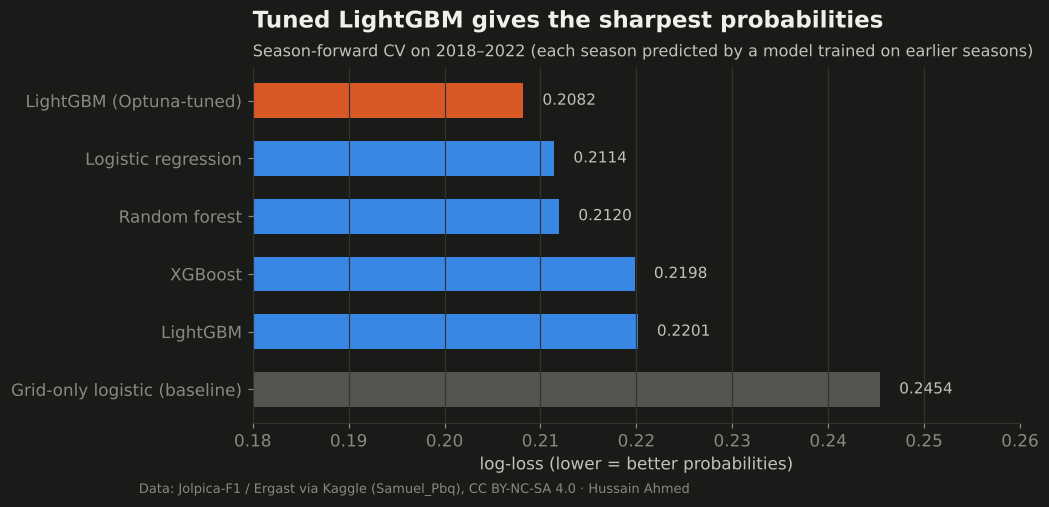

In [14]:
plot = cv_table.dropna(subset=["log_loss"]).sort_values("log_loss", ascending=False)
fig, ax = plt.subplots(figsize=(9, 4.2))
c = [ORANGE if "tuned" in m else GRAY if "baseline" in m else BLUE for m in plot.model]
ax.barh(plot.model, plot.log_loss, color=c, height=0.6)
for i, v in enumerate(plot.log_loss):
    ax.text(v + 0.002, i, f"{v:.4f}", va="center", color=INK_2, fontsize=10)
ax.set_xlim(0.18, 0.26); ax.grid(axis="y", visible=False); ax.set_xlabel("log-loss (lower = better probabilities)")
ax.set_title("Tuned LightGBM gives the sharpest probabilities")
style.subtitle(ax, "Season-forward CV on 2018–2022 (each season predicted by a model trained on earlier seasons)")
style.source(fig); plt.savefig(FIG + "07_model_comparison.png"); plt.show()

**Why tuned LightGBM?** Lowest CV log-loss and Brier score and highest ROC-AUC/PR-AUC of all candidates. Optuna chose a
*small, heavily regularised* model (4 leaves, ≥139 rows per leaf, slow learning rate): with ~20 cars per race
the signal is mostly a few strong effects (grid, team form), so simple trees generalise best.

## 4. Final test — 2023 to 2026 (evaluated once)

In [15]:
final = lgbm_from(best_params).fit(dev[FEATURES], dev[TARGET])
base = make_models()["Grid-only logistic (baseline)"][1].fit(dev[["grid_pos"]], dev[TARGET])
p_test = final.predict_proba(test[FEATURES])[:, 1]
p_base = base.predict_proba(test[["grid_pos"]])[:, 1]
test_metrics = {"model": metrics(test, test[TARGET].values, p_test),
                "grid_only_baseline": metrics(test, test[TARGET].values, p_base),
                "rule_top3_grid": {"podium_hits_per_race": float(race_top3_hits(test, -test.grid_pos.values).mean()),
                                   "winner_hit_rate": race_winner_hit(test, -test.grid_pos.values)}}
by_year = []
for y in TEST_YEARS:
    m = test.year == y
    by_year.append({"year": y, "races": int(test[m].raceId.nunique()),
                    "model_log_loss": metrics(test[m], test[m][TARGET].values, p_test[m])["log_loss"],
                    "baseline_log_loss": metrics(test[m], test[m][TARGET].values, p_base[m])["log_loss"],
                    "model_podium_hits": float(race_top3_hits(test[m], p_test[m]).mean()),
                    "grid_rule_podium_hits": float(race_top3_hits(test[m], -test[m].grid_pos.values).mean())})
by_year = pd.DataFrame(by_year)
display(pd.DataFrame(test_metrics).T.round(4)); by_year.round(3)

,roc_auc,pr_auc,log_loss,brier,podium_hits_per_race,winner_hit_rate
model,0.9427,0.7359,0.2089,0.0647,2.0222,0.6778
grid_only_baseline,0.9186,0.6808,0.2429,0.0692,2.0111,0.6111
rule_top3_grid,NaN,NaN,NaN,NaN,2.0111,0.6111


,year,races,model_log_loss,baseline_log_loss,model_podium_hits,grid_rule_podium_hits
0,2023,22,0.220,0.268,1.955,1.955
1,2024,24,0.222,0.243,2.000,2.000
2,2025,24,0.196,0.232,2.292,2.250
3,2026,20,0.197,0.229,1.800,1.800


In [16]:
ll_gain = 1 - test_metrics["model"]["log_loss"] / test_metrics["grid_only_baseline"]["log_loss"]
print(f"Log-loss improvement over the grid-only model on 2023–2026: {ll_gain:.1%}")
facts["test_logloss_improvement"] = round(float(ll_gain), 4)

Log-loss improvement over the grid-only model on 2023–2026: 14.0%


### 4.1 Are the probabilities honest? (calibration)

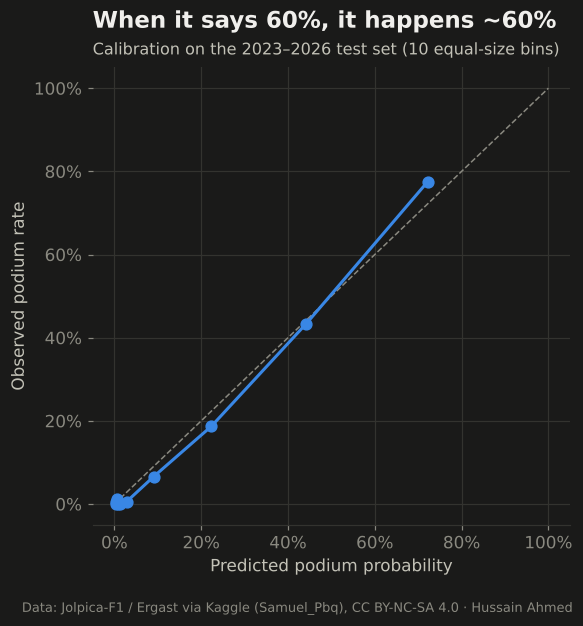

In [17]:
frac, mean_p = calibration_curve(test[TARGET], p_test, n_bins=10, strategy="quantile")
fig, ax = plt.subplots(figsize=(5.6, 5.4))
ax.plot([0, 1], [0, 1], color=MUTED, lw=1, ls="--")
ax.plot(mean_p, frac, color=BLUE, marker="o", markersize=7)
ax.set_xlabel("Predicted podium probability"); ax.set_ylabel("Observed podium rate")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_title("When it says 60%, it happens ~60%")
style.subtitle(ax, "Calibration on the 2023–2026 test set (10 equal-size bins)")
style.source(fig); plt.savefig(FIG + "08_calibration.png"); plt.show()

### 4.2 What drives a podium? (SHAP on the test set)

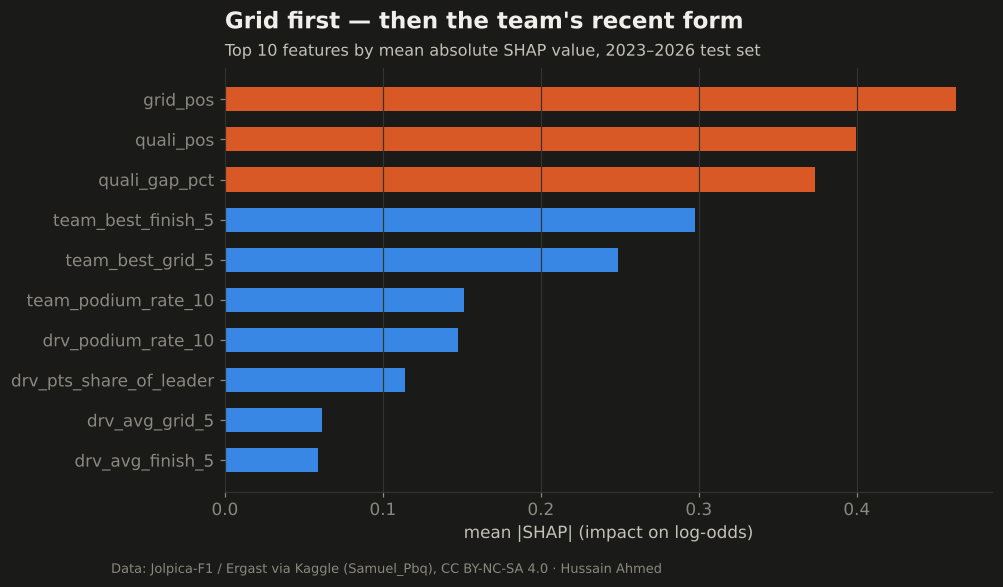

In [18]:
explainer = shap.TreeExplainer(final)
sv = explainer.shap_values(test[FEATURES])
sv = sv[1] if isinstance(sv, list) else sv
imp = pd.Series(np.abs(sv).mean(axis=0), index=FEATURES).sort_values(ascending=False)
facts["shap_top"] = imp.head(8).round(4).to_dict()
top = imp.head(10)[::-1]
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(top.index, top.values, color=[ORANGE if i >= len(top) - 3 else BLUE for i in range(len(top))], height=0.6)
ax.grid(axis="y", visible=False); ax.set_xlabel("mean |SHAP| (impact on log-odds)")
ax.set_title("Grid first — then the team's recent form")
style.subtitle(ax, "Top 10 features by mean absolute SHAP value, 2023–2026 test set")
style.source(fig); plt.savefig(FIG + "09_shap_importance.png"); plt.show()

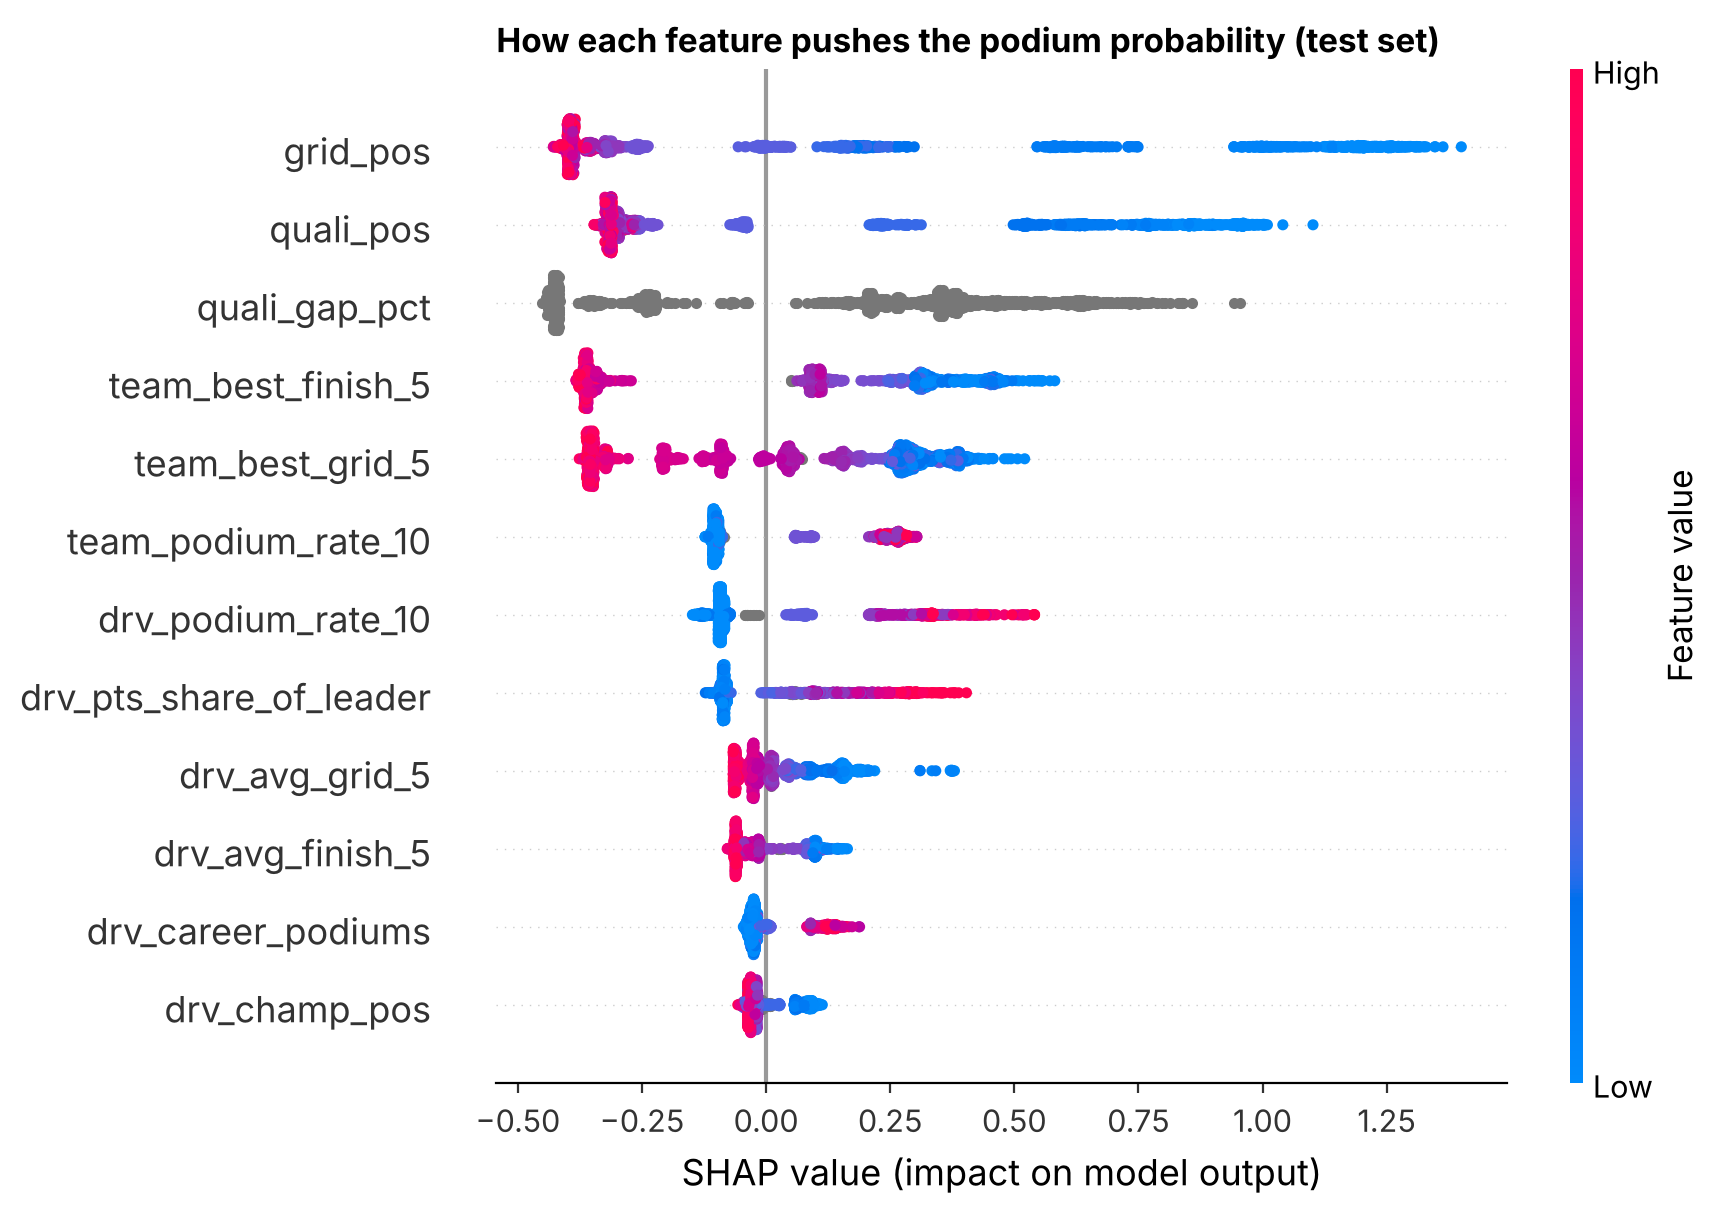

In [19]:
with plt.style.context("default"):
    shap.summary_plot(sv, test[FEATURES], max_display=12, show=False, plot_size=(9, 6))
    plt.title("How each feature pushes the podium probability (test set)", loc="left", fontweight="bold")
    plt.savefig(FIG + "10_shap_beeswarm.png", dpi=150, bbox_inches="tight"); plt.show()

### 4.3 Case studies — races the grid got wrong

In [20]:
tp = test[["raceId", "year", "round", "name", "driverId", "constructorId", "grid_pos", "positionOrder", "podium"]].copy()
tp["p_model"], tp["p_grid_baseline"] = p_test, p_base
tp = tp.merge(t["drivers"][["driverId", "forename", "surname", "code"]], on="driverId") \
       .merge(t["constructors"][["constructorId", "name"]].rename(columns={"name": "team"}), on="constructorId")
tp.to_csv(RES + "test_predictions.csv", index=False)
# podium finishers who started outside the top 5: who did the model rate higher than the grid did?
surprise = tp[(tp.podium == 1) & (tp.grid_pos > 5)].copy()
surprise["lift"] = surprise.p_model / surprise.p_grid_baseline
facts["surprise_podiums"] = int(len(surprise))
facts["surprise_model_higher_share"] = round(float((surprise.p_model > surprise.p_grid_baseline).mean()), 3)
print(f"{len(surprise)} podiums from P6 or lower; the model gave a higher chance than the grid-only model in "
      f"{facts['surprise_model_higher_share']:.0%} of them")
surprise.sort_values("grid_pos", ascending=False)[["year", "name", "surname", "team", "grid_pos", "positionOrder", "p_grid_baseline", "p_model"]].head(10).round(3)

32 podiums from P6 or lower; the model gave a higher chance than the grid-only model in 84% of them


,year,name,surname,team,grid_pos,positionOrder,p_grid_baseline,p_model
1799,2026,Brazilian Grand Prix,Verstappen,Red Bull,21,2,0.000,0.210
1309,2025,São Paulo Grand Prix,Verstappen,Red Bull,19,3,0.001,0.194
893,2024,Abu Dhabi Grand Prix,Leclerc,Ferrari,19,3,0.001,0.155
1131,2025,British Grand Prix,Hülkenberg,Sauber,19,3,0.001,0.007
1644,2026,Italian Grand Prix,Antonelli,Mercedes,19,1,0.001,0.241
1329,2025,Las Vegas Grand Prix,Antonelli,Mercedes,17,3,0.001,0.065
833,2024,São Paulo Grand Prix,Verstappen,Red Bull,17,1,0.001,0.148
21,2023,Saudi Arabian Grand Prix,Verstappen,Red Bull,15,2,0.004,0.267
162,2023,Austrian Grand Prix,Pérez,Red Bull,15,3,0.004,0.150
835,2024,São Paulo Grand Prix,Gasly,Alpine F1 Team,13,3,0.009,0.004


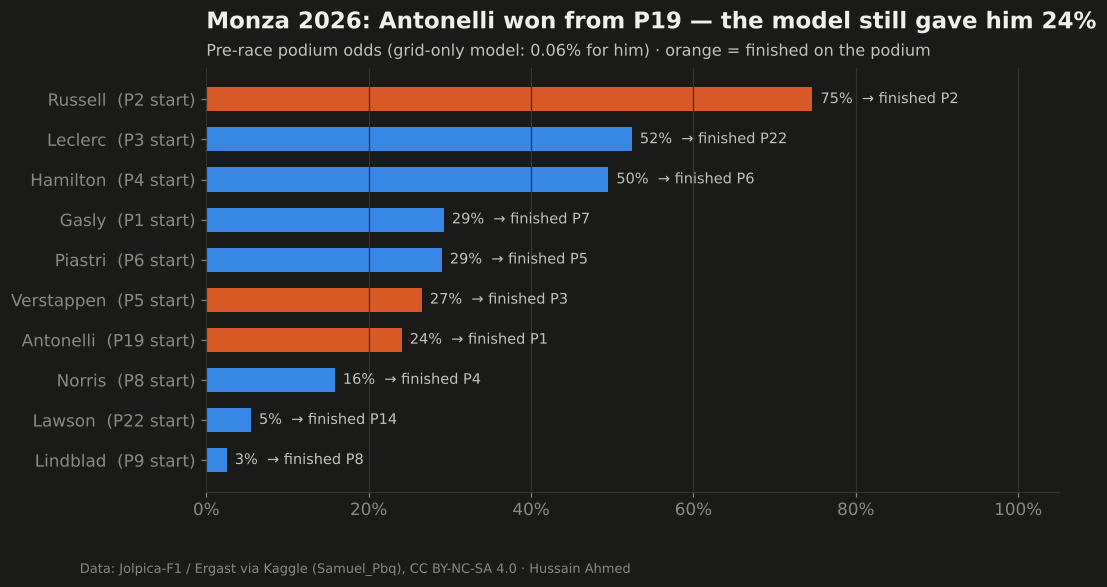

In [21]:
case = tp[(tp.year == 2026) & (tp.name == "Italian Grand Prix")].sort_values("p_model", ascending=False)
facts["case_monza_2026"] = case.head(6)[["surname", "team", "grid_pos", "positionOrder", "p_model", "p_grid_baseline"]].round(3).to_dict(orient="records")
fig, ax = plt.subplots(figsize=(10, 5))
d = case.head(10)[::-1]
c = [ORANGE if p == 1 else BLUE for p in d.podium]
ax.barh(d.surname + "  (P" + d.grid_pos.astype(int).astype(str) + " start)", d.p_model * 100, color=c, height=0.6)
for i, (pm, fin) in enumerate(zip(d.p_model, d.positionOrder)):
    ax.text(pm * 100 + 1, i, f"{pm:.0%}  → finished P{fin}", va="center", color=INK_2, fontsize=9.5)
ax.xaxis.set_major_formatter(mtick.PercentFormatter()); ax.set_xlim(0, 105); ax.grid(axis="y", visible=False)
ant = case[case.surname == "Antonelli"].iloc[0]
facts["case_antonelli"] = {"grid": int(ant.grid_pos), "p_model": round(float(ant.p_model), 4), "p_grid_baseline": round(float(ant.p_grid_baseline), 4)}
ax.set_title(f"Monza 2026: Antonelli won from P{int(ant.grid_pos)} — the model still gave him {ant.p_model:.0%}")
style.subtitle(ax, f"Pre-race podium odds (grid-only model: {ant.p_grid_baseline:.2%} for him) · orange = finished on the podium")
style.source(fig); plt.savefig(FIG + "11_case_monza_2026.png"); plt.show()

## 5. Save everything

In [22]:
# production model: same tuned settings, trained on ALL seasons (used by the Streamlit what-if tab)
prod = lgbm_from(best_params).fit(df[FEATURES], df[TARGET])
joblib.dump({"model": prod, "features": FEATURES, "params": best_params}, "../models/podium_lgbm.joblib")
out = {"facts": facts, "cv_table": cv_table.round(4).to_dict(orient="records"),
       "cv_folds_tuned": tuned_cv.round(4).to_dict(orient="records"), "best_params": best_params,
       "test": test_metrics, "test_by_year": by_year.round(4).to_dict(orient="records"),
       "features": FEATURES}
json.dump(out, open(RES + "metrics.json", "w"), indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))
df.to_csv("../data/model_table.csv", index=False)
print("saved")

saved


## 6. Limitations & next steps
* Pre-race model: it cannot know about crashes, safety cars or rain — the reason even a perfect model misses podiums.
* 2026 is a new rules era; the model has only 2026's own previous rounds to learn the new pecking order (rolling form features adapt race by race).
* Qualifying 1994–2002 is incomplete in the source, so the model starts in 2006.
* Next: add practice-session pace (available only 2025–26), weather data, and a race-simulation of the championship.